In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
df=pd.read_csv("diabetes_prediction_dataset.csv")

In [14]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


In [15]:
df.isna().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [16]:
df.describe()


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [23]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['diabetes'])
y = df['diabetes']

X_train, X_test, Y_train, Y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [28]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Define columns
categorical_cols = ['gender', 'smoking_history']

numerical_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

binary_cols = ['hypertension', 'heart_disease']

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        ('bin', 'passthrough', binary_cols)
    ]
)

# Fit on training data
X_train_scaled = preprocessor.fit_transform(X_train)

# Transform test data
X_test_scaled = preprocessor.transform(X_test)

In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
categorical_cols=["gender","smoking_history"]
numerical_cols=["age","bmi","HbA1c_level","blood_glucose_level"]
binary_cols=["hypertension","heart_disease"]

preprocessor=ColumnTransformer(
    transformers=[
        ("num",StandardScaler(),numerical_cols),
        ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_cols),
        ("bin","passthrough",binary_cols)

    ]

)
X_train_scaled=preprocessor.fit_transform(X_train)
X_test_scaled=preprocessor.transform(X_test)

In [33]:
print(
X_train_scaled)

[[ 1.69106976e+00  4.72203802e-04  9.08249004e-01 ...  0.00000000e+00
   1.00000000e+00  0.00000000e+00]
 [-1.01645993e+00 -3.21771551e-01 -9.59680097e-01 ...  0.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [-2.61902476e-01 -2.05824032e-01  1.00164546e+00 ...  0.00000000e+00
   0.00000000e+00  0.00000000e+00]
 ...
 [ 4.48269246e-01  4.72203802e-04  2.54473819e-01 ...  0.00000000e+00
   1.00000000e+00  0.00000000e+00]
 [-1.63786019e+00 -1.75229289e+00  6.28059639e-01 ...  0.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [-1.68224592e+00  4.72203802e-04 -1.42666237e+00 ...  0.00000000e+00
   0.00000000e+00  0.00000000e+00]]


In [25]:
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (80000, 15)
Testing shape: (20000, 15)


In [34]:
print("Training shape:",X_train_scaled.shape)
print("Testing shape:",X_test_scaled.shape)

Training shape: (80000, 15)
Testing shape: (20000, 15)


In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

model = LogisticRegression()

model.fit(X_train_scaled, Y_train)

y_pred = model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(Y_test, y_pred))
print(classification_report(Y_test, y_pred))

Accuracy: 0.96045
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     18300
           1       0.86      0.64      0.73      1700

    accuracy                           0.96     20000
   macro avg       0.91      0.81      0.86     20000
weighted avg       0.96      0.96      0.96     20000



In [41]:
from sklearn.metrics import accuracy_score,classification_report
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model.fit(X_train_scaled,Y_train)
y_pred=model.predict(X_test_scaled)
print("accuracy_score:",accuracy_score(Y_test,Y_pred))
print(classification_report(Y_test,y_pred))

accuracy_score: 0.96045
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     18300
           1       0.86      0.64      0.73      1700

    accuracy                           0.96     20000
   macro avg       0.91      0.81      0.86     20000
weighted avg       0.96      0.96      0.96     20000



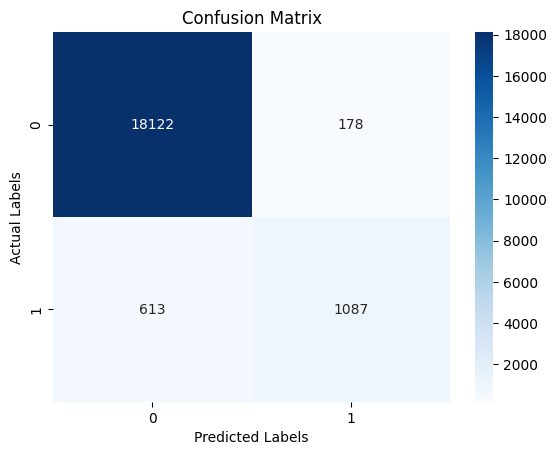

In [44]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(Y_test,Y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")
plt.show()

In [46]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=2000, solver='liblinear'))
])

In [55]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    'model__C': [1, 0.2, 1, 10, 100],
    'model__penalty': ['l1', 'l2'],
    'model__class_weight': [None, 'balanced']
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, Y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,estimator,Pipeline(step...liblinear'))])
,param_grid,"{'model__C': [1, 0.2, ...], 'model__class_weight': [None, 'balanced'], 'model__penalty': ['l1', 'l2']}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...), ...]"


In [56]:
print("Best Parameters:", grid_search.best_params_)

print("Best CV F1 Score:", grid_search.best_score_)

Best Parameters: {'model__C': 1, 'model__class_weight': None, 'model__penalty': 'l1'}
Best CV F1 Score: 0.7288309328951492


In [57]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

print("Accuracy:", accuracy_score(Y_test, y_pred))
print("Precision:", precision_score(Y_test, y_pred))
print("Recall:", recall_score(Y_test, y_pred))
print("F1 Score:", f1_score(Y_test, y_pred))

print("\nClassification Report:")
print(classification_report(Y_test, y_pred))

Accuracy: 0.9605
Precision: 0.8593996840442338
Recall: 0.64
F1 Score: 0.7336480107889414

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     18300
           1       0.86      0.64      0.73      1700

    accuracy                           0.96     20000
   macro avg       0.91      0.82      0.86     20000
weighted avg       0.96      0.96      0.96     20000

